# 03 — Poder estatístico, tamanho de amostra e múltiplos testes

> **stats-foundations · Fase 1** — planejar o teste *antes* de rodar e corrigir quando comparo várias coisas.

No [notebook 02](02-intervalos-confianca-teste-hipotese.ipynb) aprendi a *analisar* um teste A/B depois
que ele rodou. Aqui fecho a tríade com as duas peças que separam quem testa por método de quem testa
no improviso:

1. **Poder estatístico + tamanho de amostra** — *antes* de subir o teste: quantos leads e por quanto
   tempo, para ter chance real de detectar o efeito. É a matemática da skill `tamanho-amostra-teste`.
2. **Correção para múltiplos testes** — quando comparo várias métricas ou variantes ao mesmo tempo,
   o risco de falso positivo explode. É a armadilha mais comum (e silenciosa) em agência.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

RNG = np.random.default_rng(42)
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})
print("ok")

ok


## A. Poder estatístico

### Os dois erros e os quatro botões

Um teste pode errar de dois jeitos:

- **Erro Tipo I (α):** dizer que há diferença quando não há → *falso positivo* (escalo uma variação que
  não é melhor). Controlado por α (tipicamente 5%).
- **Erro Tipo II (β):** não detectar uma diferença que existe → *falso negativo* (descarto um vencedor).

O **poder** é `1 − β`: a chance de detectar um efeito que realmente existe. Padrão de mercado: **80%**.

Quatro botões estão amarrados — fixe três e o quarto fica determinado:
**α**, **poder**, **tamanho do efeito (MDE)** e **tamanho da amostra (n)**.

In [2]:
# Poder de um teste z de duas proporções (n = leads POR variação)
def poder(n, p1, p2, alpha=0.05):
    delta = abs(p2 - p1)
    pbar = (p1 + p2) / 2
    se0 = np.sqrt(2 * pbar * (1 - pbar))          # sob H0 (pooled)
    se1 = np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))  # sob H1
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    return stats.norm.cdf((np.sqrt(n) * delta - z_alpha * se0) / se1)

# Exemplo: baseline 12% -> 15% (efeito de +3 p.p.)
p1, p2 = 0.12, 0.15
for n in [200, 500, 1000, 2000, 3000]:
    print(f"n={n:>5} por variação  ->  poder = {poder(n, p1, p2):.1%}")

n=  200 por variação  ->  poder = 13.9%
n=  500 por variação  ->  poder = 28.4%
n= 1000 por variação  ->  poder = 50.1%
n= 2000 por variação  ->  poder = 79.3%
n= 3000 por variação  ->  poder = 92.5%


### Curva de poder: poder × tamanho da amostra

A curva mostra quanto de amostra preciso para cruzar os 80% de poder. Antes desse ponto, o teste
provavelmente **não enxerga** o efeito mesmo que ele exista.

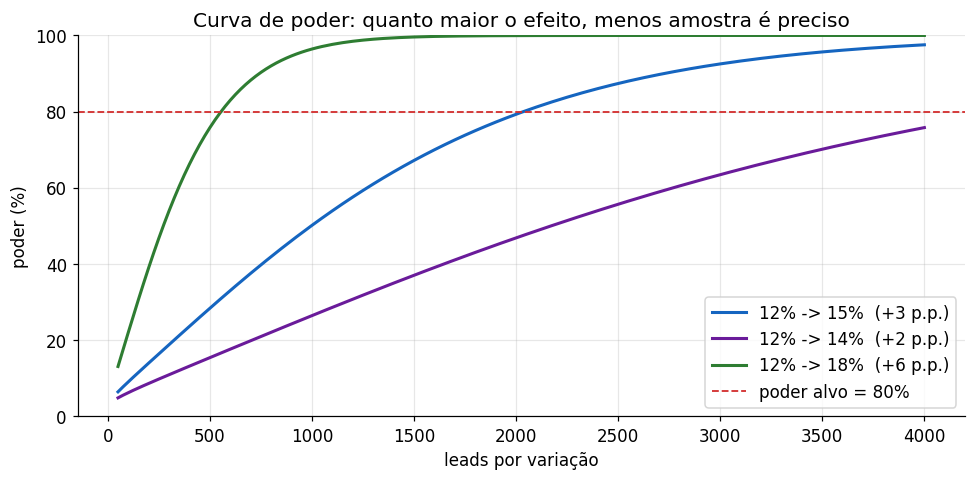

In [3]:
ns = np.arange(50, 4001, 25)
fig, ax = plt.subplots(figsize=(9, 4.5))
for (a, b), cor in [((0.12, 0.15), "#1565c0"), ((0.12, 0.14), "#6a1b9a"),
                    ((0.12, 0.18), "#2e7d32")]:
    pw = [poder(n, a, b) for n in ns]
    ax.plot(ns, np.array(pw) * 100, color=cor, lw=2,
            label=f"{a:.0%} -> {b:.0%}  (+{(b-a)*100:.0f} p.p.)")
ax.axhline(80, color="#d32f2f", ls="--", lw=1.2, label="poder alvo = 80%")
ax.set_title("Curva de poder: quanto maior o efeito, menos amostra é preciso")
ax.set_xlabel("leads por variação"); ax.set_ylabel("poder (%)")
ax.set_ylim(0, 100); ax.legend()
fig.tight_layout(); plt.show()

## B. Tamanho mínimo de amostra

Inverter a conta do poder responde a pergunta operacional: *"de quantos leads por variação eu preciso?"*.
Esta é exatamente a fórmula dentro da skill `tamanho-amostra-teste`.

In [4]:
def amostra_minima(p1, p2, alpha=0.05, power=0.80):
    delta = abs(p2 - p1)
    pbar = (p1 + p2) / 2
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    num = (z_a * np.sqrt(2 * pbar * (1 - pbar)) +
           z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return int(np.ceil(num / delta ** 2))

base = 0.12
print(f"Baseline {base:.0%} | poder 80% | confiança 95%\n")
for mde_rel in [0.10, 0.15, 0.25, 0.50]:
    alvo = base * (1 + mde_rel)
    n = amostra_minima(base, alvo)
    print(f"detectar +{mde_rel:.0%} (chegar a {alvo:.1%})  ->  {n:>5} leads/variação "
          f"({2*n} no total)")

Baseline 12% | poder 80% | confiança 95%

detectar +10% (chegar a 13.2%)  ->  12004 leads/variação (24008 no total)
detectar +15% (chegar a 13.8%)  ->   5443 leads/variação (10886 no total)
detectar +25% (chegar a 15.0%)  ->   2036 leads/variação (4072 no total)
detectar +50% (chegar a 18.0%)  ->    555 leads/variação (1110 no total)


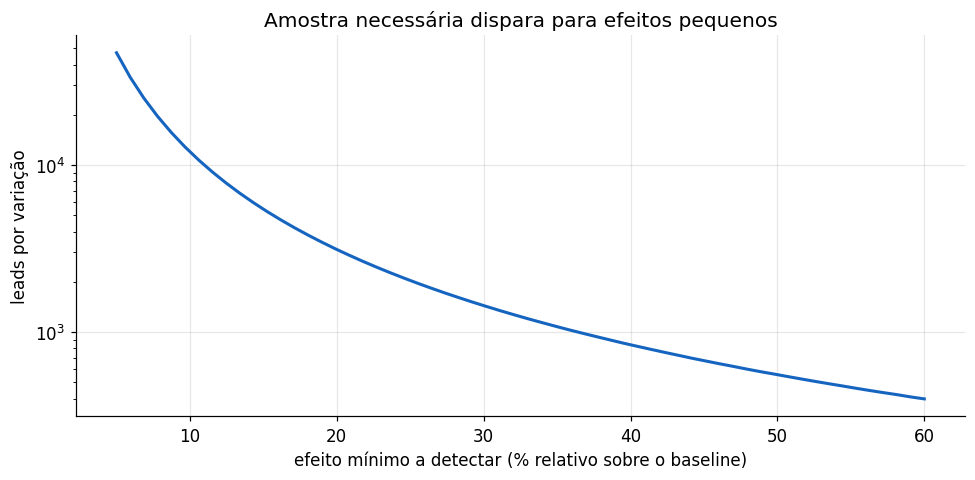

Lição: provar uma melhoria pequena (+5%) custa MUITO mais amostra que uma grande (+30%).


In [5]:
# Quanto menor o efeito que quero detectar, mais cara fica a amostra (cresce ~1/efeito^2)
mdes = np.linspace(0.05, 0.60, 60)   # efeito relativo
base = 0.12
ns = [amostra_minima(base, base * (1 + m)) for m in mdes]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(mdes * 100, ns, color="#1565c0", lw=2)
ax.set_title("Amostra necessária dispara para efeitos pequenos")
ax.set_xlabel("efeito mínimo a detectar (% relativo sobre o baseline)")
ax.set_ylabel("leads por variação")
ax.set_yscale("log")
fig.tight_layout(); plt.show()
print("Lição: provar uma melhoria pequena (+5%) custa MUITO mais amostra que uma grande (+30%).")

## C. Correção para múltiplos testes

### A armadilha

Se eu testo **uma** métrica a α=5%, tenho 5% de chance de falso positivo. Mas se num mesmo teste eu
olho **10 métricas** (CTR, CPL, conversão, ticket, ROAS…) e comemoro a primeira que "deu
significativa", a chance de **pelo menos um falso positivo** é:

$$ 1 - (1 - 0{,}05)^{10} \approx 40\% $$

Ou seja: testando muita coisa, é quase garantido achar "significância" no ruído. Duas correções:

- **Bonferroni:** use α/m em cada teste (m = nº de testes). Simples e conservador.
- **Benjamini-Hochberg (FDR):** controla a *proporção* de falsos positivos entre os significativos;
  menos conservador, melhor quando há muitos testes.

In [6]:
# Simulação: m métricas SEM efeito real. Com que frequência aparece >=1 falso positivo?
m = 10
n_sim = 20_000
alpha = 0.05

falsos_sem_correcao = 0
falsos_com_bonferroni = 0
for _ in range(n_sim):
    pvals = RNG.uniform(0, 1, m)          # sob H0, p-valor ~ Uniforme(0,1)
    if (pvals < alpha).any():
        falsos_sem_correcao += 1
    if (pvals < alpha / m).any():         # Bonferroni
        falsos_com_bonferroni += 1

print(f"Testando {m} métricas, todas SEM efeito real:")
print(f"  P(>=1 falso positivo) SEM correção : {falsos_sem_correcao/n_sim:.1%}")
print(f"  P(>=1 falso positivo) com Bonferroni: {falsos_com_bonferroni/n_sim:.1%}  (volta para ~5%)")

Testando 10 métricas, todas SEM efeito real:
  P(>=1 falso positivo) SEM correção : 39.9%
  P(>=1 falso positivo) com Bonferroni: 5.1%  (volta para ~5%)


Variante      p-valor   bruto<0.05   Bonferroni   BH (FDR)
Vídeo A         0.004          SIM          SIM        SIM
Vídeo B         0.011          SIM            -        SIM
Estático C      0.039          SIM            -          -
Carrossel D     0.041          SIM            -          -
UGC E           0.200            -            -          -
Meme F          0.510            -            -          -


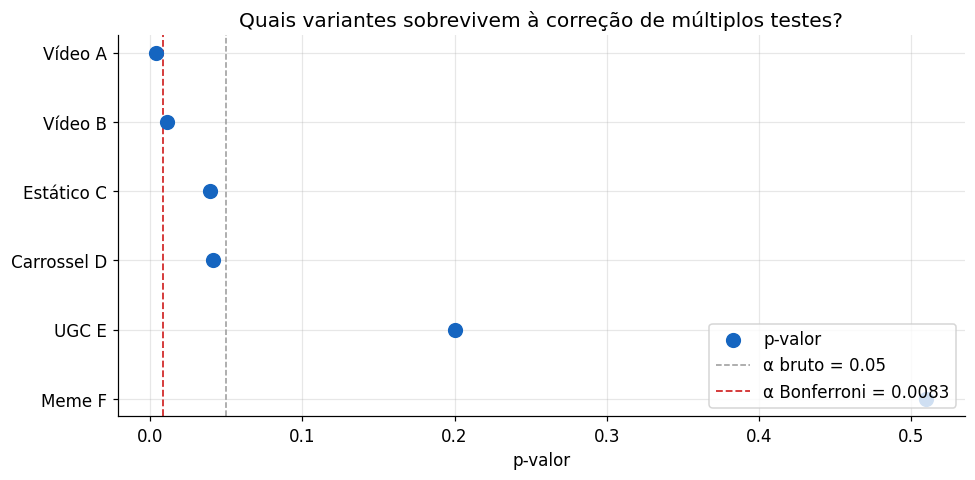

In [7]:
# Exemplo concreto: 6 variantes de criativo testadas contra o controle
nomes = ["Vídeo A", "Vídeo B", "Estático C", "Carrossel D", "UGC E", "Meme F"]
pvals = np.array([0.004, 0.011, 0.039, 0.041, 0.20, 0.51])
m = len(pvals)
alpha = 0.05

# Bonferroni
sig_bonf = pvals < alpha / m
# Benjamini-Hochberg (FDR)
ordem = np.argsort(pvals)
thresholds = (np.arange(1, m + 1) / m) * alpha
passou = pvals[ordem] <= thresholds
k = np.where(passou)[0].max() + 1 if passou.any() else 0
sig_bh = np.zeros(m, dtype=bool)
if k > 0:
    sig_bh[ordem[:k]] = True

print(f"{'Variante':<12}{'p-valor':>9}{'  bruto<0.05':>13}{'  Bonferroni':>13}{'  BH (FDR)':>11}")
for i in range(m):
    print(f"{nomes[i]:<12}{pvals[i]:>9.3f}"
          f"{('  SIM' if pvals[i] < alpha else '  -'):>13}"
          f"{('  SIM' if sig_bonf[i] else '  -'):>13}"
          f"{('  SIM' if sig_bh[i] else '  -'):>11}")

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(m)[::-1]
ax.scatter(pvals, y, s=80, color="#1565c0", zorder=3, label="p-valor")
ax.axvline(alpha, color="#999", ls="--", lw=1, label=f"α bruto = {alpha}")
ax.axvline(alpha / m, color="#d32f2f", ls="--", lw=1.2, label=f"α Bonferroni = {alpha/m:.4f}")
ax.set_yticks(y); ax.set_yticklabels(nomes)
ax.set_title("Quais variantes sobrevivem à correção de múltiplos testes?")
ax.set_xlabel("p-valor"); ax.legend(loc="lower right")
fig.tight_layout(); plt.show()

## Resumo — planejar e corrigir

| Conceito | Pergunta de negócio | Regra prática |
|---|---|---|
| **Poder (1−β)** | "meu teste consegue enxergar o efeito?" | mirar 80%; abaixo disso o teste é cego |
| **Tamanho de amostra** | "quantos leads e por quantos dias?" | calcular *antes*; efeitos pequenos custam muito |
| **Múltiplos testes** | "olhei 10 métricas e uma deu — confio?" | corrigir (Bonferroni / BH), senão ~40% de falso positivo |

**Como isto vira ferramenta:** a parte de amostra já está na skill `tamanho-amostra-teste`. A correção
de múltiplos testes é a próxima skill candidata (`correcao-multiplos-testes`).

**Próximo passo do plano:** o **mini-projeto A/B simulado** (entregável da Semana 4) — um repositório
próprio que junta os três notebooks: calcula a amostra antes, simula o teste, analisa com IC + p-valor,
corrige múltiplas métricas e fecha com um relatório executivo.